<center><h1>Do_Mimi_HW1</h1></center>
<br>
<center><font size="4">Vertebral Column Data</font></center>

USC ID: 8125-6556-10

### (a) Download Data

Package imports

In [19]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.neighbors import KNeighborsClassifier
from sklearn.metrics import confusion_matrix, recall_score, precision_score, f1_score, accuracy_score
from scipy.io import arff

Get the Vertebral Column Data Set

In [20]:
data, meta = arff.loadarff("../data/column_2C_weka.arff")

df = pd.DataFrame(data)

df["class"] = df["class"].str.decode("utf-8")       # convert bytes to string

df["class"] = df["class"].map({"Normal": 0, "Abnormal": 1})     #convert labels to 0 and 1

df.head()

,pelvic_incidence,pelvic_tilt,lumbar_lordosis_angle,sacral_slope,pelvic_radius,degree_spondylolisthesis,class
0,63.027817,22.552586,39.609117,40.475232,98.672917,-0.254400,1
1,39.056951,10.060991,25.015378,28.995960,114.405425,4.564259,1
2,68.832021,22.218482,50.092194,46.613539,105.985135,-3.530317,1
3,69.297008,24.652878,44.311238,44.644130,101.868495,11.211523,1
4,49.712859,9.652075,28.317406,40.060784,108.168725,7.918501,1


### (b) Pre-Processing and Exploratory Data Analysis

#### i. Scatterplots

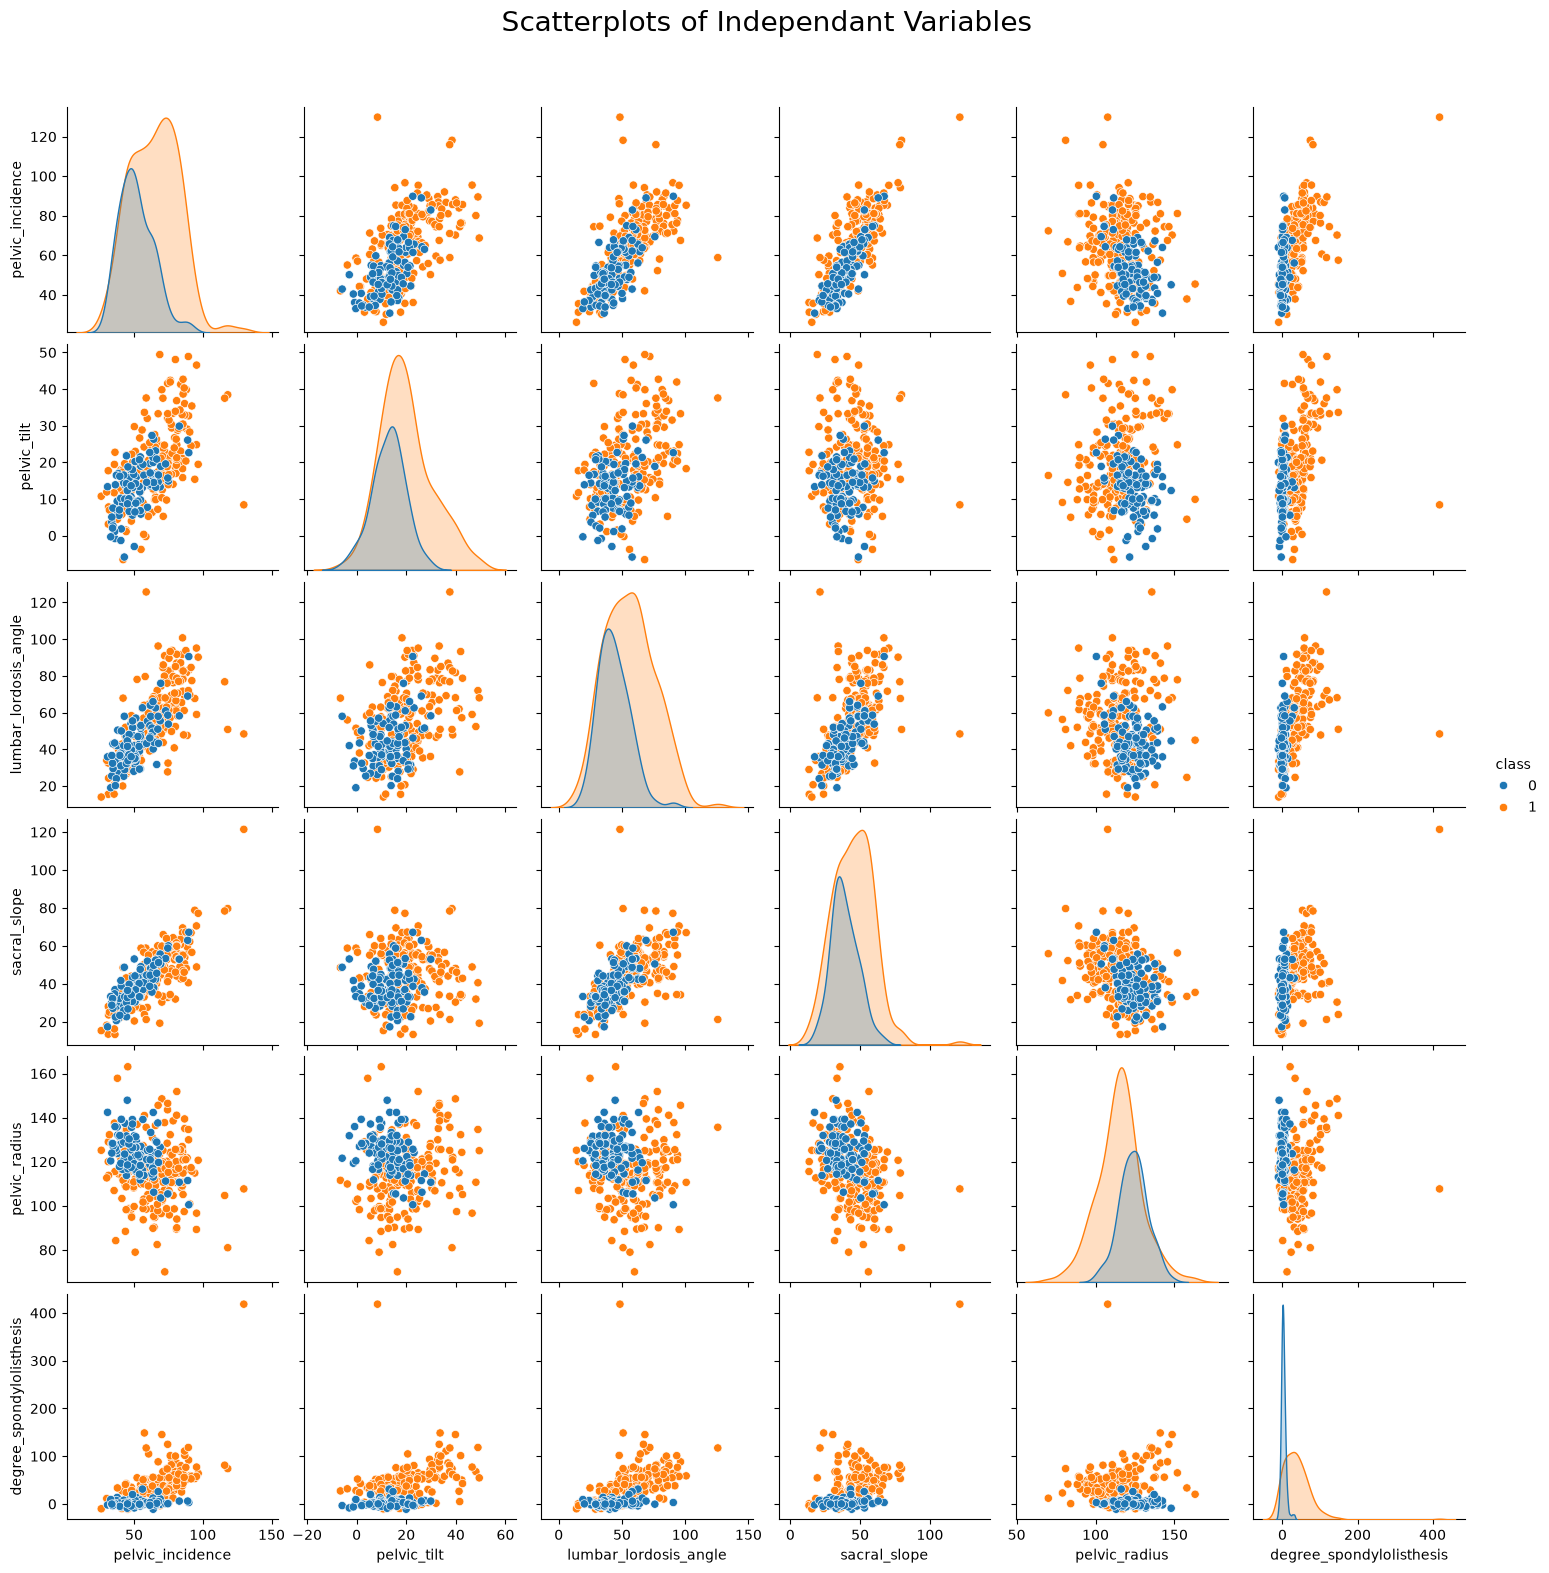

In [21]:
scatterplots = sns.pairplot(df,
             vars = [
                 "pelvic_incidence",
                 "pelvic_tilt",
                 "lumbar_lordosis_angle",
                 "sacral_slope",
                 "pelvic_radius",
                 "degree_spondylolisthesis"],
                hue = "class"
            )

scatterplots.figure.suptitle("Scatterplots of Independant Variables", y = 1.05, fontsize = 20)

plt.show()

#### ii. Boxplots

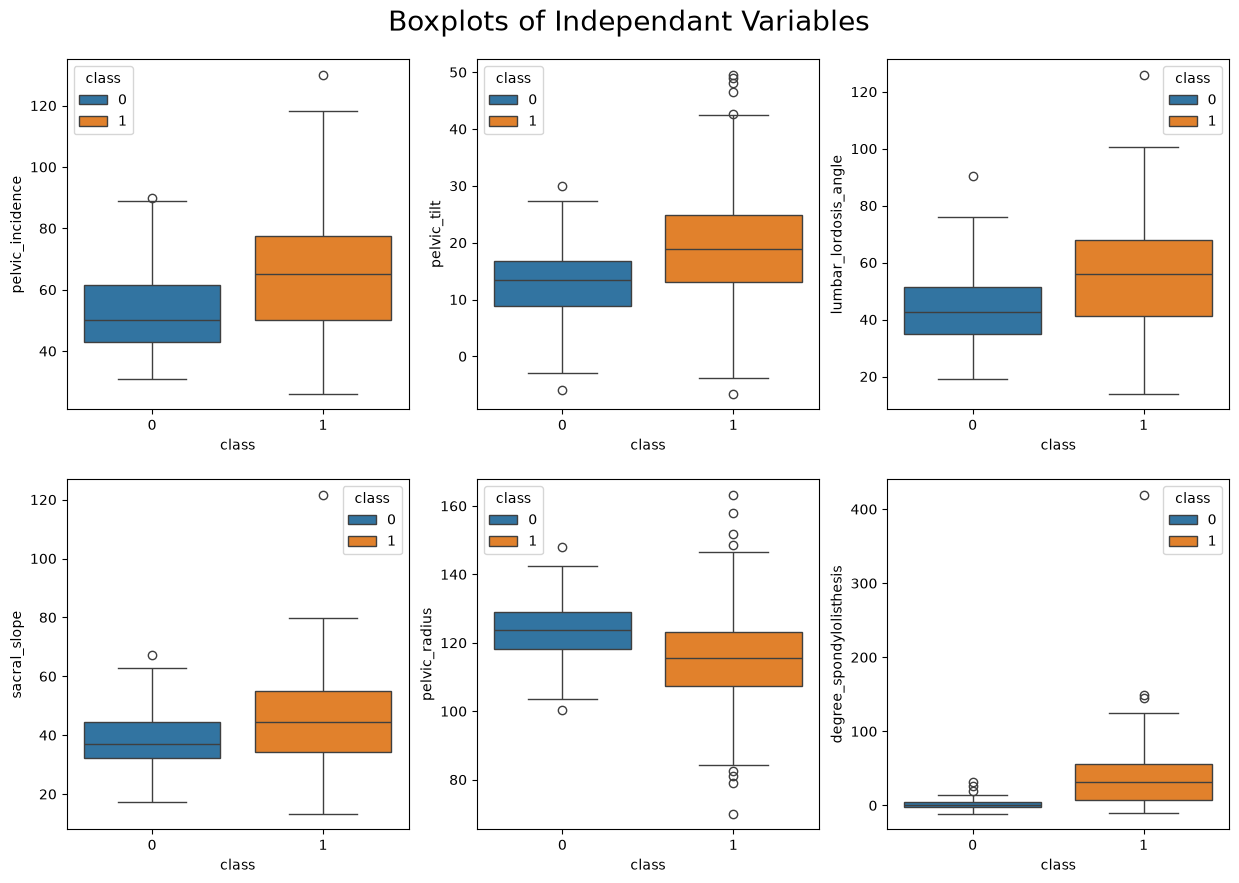

In [22]:
fig, axes = plt.subplots(2, 3, figsize = (15, 10))

sns.boxplot(data = df, x = "class", y = "pelvic_incidence", hue = "class", ax = axes[0, 0])
sns.boxplot(data = df, x = "class", y = "pelvic_tilt", hue = "class", ax = axes[0, 1])
sns.boxplot(data = df, x = "class", y = "lumbar_lordosis_angle", hue = "class", ax = axes[0, 2])
sns.boxplot(data = df, x = "class", y = "sacral_slope", hue = "class", ax = axes[1, 0])
sns.boxplot(data = df, x = "class", y = "pelvic_radius", hue = "class", ax = axes[1, 1])
sns.boxplot(data = df, x = "class", y = "degree_spondylolisthesis", hue = "class", ax = axes[1, 2])

fig.suptitle("Boxplots of Independant Variables", y = 0.93, fontsize = 20)

plt.show()


#### iii. Split Data Set

In [23]:
class_0 = df[df["class"] == 0]
class_1 = df[df["class"] == 1]

train_0 = class_0.iloc[:70]      # .iloc selects rows by position
train_1 = class_1.iloc[:140]

test_0 = class_0.iloc[70:]
test_1 = class_1.iloc[140:]

train_set = pd.concat([train_0, train_1])
test_set = pd.concat([test_0, test_1])


### (c) Classification

#### i. Euclidean Metric

In [24]:
X_train = train_set.drop(columns = "class")     # drop class bc don't want model to know the answer
y_train = train_set["class"]                    # correct class

X_test = test_set.drop(columns = "class")       # X = features
y_test = test_set["class"]                      # y = labels

# I have already imported KNeighborsClassifier in the 1st cell which includes all of my packages

#### ii. Test Data

In [25]:
k_values = range(208, 0, -1)

train_errors = []
test_errors = []

for k in k_values:
    knn = KNeighborsClassifier(
        n_neighbors = k,
        metric = "euclidean"
    )

    knn.fit(X_train, y_train)           # gives classifier training set (X, y) 

    train_predict = knn.predict(X_train)     # predict class labels (X)
    test_predict = knn.predict(X_test)

    train_accuracy = accuracy_score(y_train, train_predict)       # (y_true, y_pred)
    test_accuracy = accuracy_score(y_test, test_predict)

    train_error = 1 - train_accuracy
    test_error = 1 - test_accuracy

    train_errors.append(train_error)
    test_errors.append(test_error)


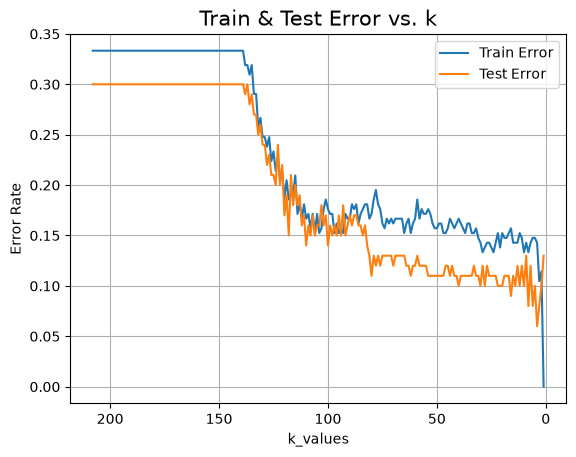

In [26]:
plt.plot(k_values, train_errors, label = "Train Error")
plt.plot(k_values, test_errors, label = "Test Error")

plt.title("Train & Test Error vs. k", fontsize = 15)
plt.xlabel("k_values")
plt.ylabel("Error Rate")
plt.grid()
plt.legend()
plt.gca().invert_xaxis()                 # get current axes, invert to show reverse order

plt.show()

In [27]:
smallest_position = np.argmin(test_errors)
best_k = list(k_values)[smallest_position]        # find k of smallest test error 
best_test_error = test_errors[smallest_position]  # find value of smallest position

print("best k =", best_k)
print("best test error =", round(best_test_error, 2))


best k = 4
best test error = 0.06


In [28]:
knn_best_k = KNeighborsClassifier(
      n_neighbors = best_k,
      metric = "euclidean"
      )

knn_best_k.fit(X_train, y_train)

y_predict_best_k = knn_best_k.predict(X_test)

cm = confusion_matrix(y_test, y_predict_best_k)

true_positive_rate = recall_score(y_test, y_predict_best_k)
true_negative_rate = recall_score(y_test, y_predict_best_k, pos_label = 0)

precision = precision_score(y_test, y_predict_best_k)

f1 = f1_score(y_test, y_predict_best_k)

print("confusion matrix =")
print(cm)
print("true positive rate =", round(true_positive_rate, 4))
print("true negative rate =", round(true_negative_rate, 4))
print("precision =", round(precision, 4))
print("f1 =", round(f1, 4))

confusion matrix =
[[25  5]
 [ 1 69]]
true positive rate = 0.9857
true negative rate = 0.8333
precision = 0.9324
f1 = 0.9583


#### iii. Learning Curve

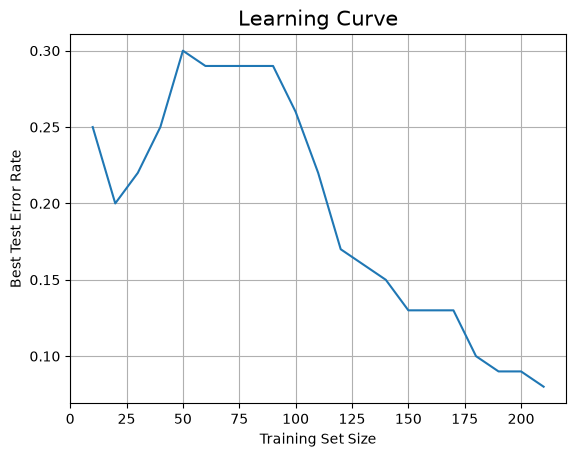

In [29]:
N_values = range(10, 211, 10)            

subset_best_test_errors = []                  

for N in N_values:
    N_class_0 = N // 3
    N_class_1 = N - N_class_0

    subset_train_class_0 = train_0.iloc[:N_class_0]
    subset_train_class_1 = train_1.iloc[:N_class_1]

    subset_train = pd.concat([subset_train_class_0, subset_train_class_1])

    X_subset_train = subset_train.drop(columns = "class")
    y_subset_train = subset_train["class"]

    k_range = range(1, N, 5)

    N_errors = []

    for k in k_range:
        knn = KNeighborsClassifier(
            n_neighbors = k,
            metric = "euclidean"
        )

        knn.fit(X_subset_train, y_subset_train)

        subset_test_predict = knn.predict(X_test)

        subset_test_accuracy = accuracy_score(y_test, subset_test_predict)
        subset_test_error = 1 - subset_test_accuracy

        N_errors.append(subset_test_error)

    subset_smallest_position = np.argmin(N_errors)
    subset_best_k = list(k_range)[subset_smallest_position]
    subset_best_test_error = N_errors[subset_smallest_position]
    subset_best_test_errors.append(subset_best_test_error)

plt.plot(N_values, subset_best_test_errors)

plt.title("Learning Curve", fontsize = 15)
plt.xlabel("Training Set Size")
plt.ylabel("Best Test Error Rate")
plt.grid()

plt.show()


### (d) Other Metrics

#### i. Minkowski Distance.

##### A. Manhattan Distance with p = 1.

In [30]:
k_range = range(1, 197, 5)

manhattan_errors = []

for k in k_range:
    knn = KNeighborsClassifier(
        n_neighbors = k,
        metric = "minkowski",
        p = 1
        )

    knn.fit(X_train, y_train)

    test_predict = knn.predict(X_test)

    test_accuracy = accuracy_score(y_test, test_predict)
    test_error = 1 - test_accuracy

    manhattan_errors.append(test_error)

smallest_position = np.argmin(manhattan_errors)
manhattan_best_k = list(k_range)[smallest_position]
manhattan_best_test_error = manhattan_errors[smallest_position]

print("manhattan best k = ", manhattan_best_k)
print("manhattan best test error =", round(manhattan_best_test_error, 2))
    

manhattan best k =  1
manhattan best test error = 0.11


##### B. With log10(p) in {0.1, 0.2, 0.3, ... ,1}.

In [31]:
log_p_range = np.arange(0.1, 1.1, 0.1)

log_p_errors = []

for log_p in log_p_range:
    p = 10 ** log_p

    knn = KNeighborsClassifier(
            n_neighbors = manhattan_best_k,
            metric = "minkowski",
            p = p
            )
    
    knn.fit(X_train, y_train)
    
    test_predict = knn.predict(X_test)
    
    test_accuracy = accuracy_score(y_test, test_predict)
    test_error = 1 - test_accuracy
    
    log_p_errors.append(test_error)
    
smallest_position = np.argmin(log_p_errors)
log_p_best = list(log_p_range)[smallest_position]
log_p_best_test_error = log_p_errors[smallest_position]
    
print("log p best =", round(log_p_best, 1))
print("log p best test error =", round(log_p_best_test_error, 2))


log p best = 0.7
log p best test error = 0.11


Best log is 0.7

##### C. Chebyshev Distance With p -> infinity.

In [32]:
k_range = range(1, 197, 5)

chebyshev_errors = []

for k in k_range:
    knn = KNeighborsClassifier(
        n_neighbors = k,
        metric = "chebyshev",
        )

    knn.fit(X_train, y_train)

    test_predict = knn.predict(X_test)

    test_accuracy = accuracy_score(y_test, test_predict)
    test_error = 1 - test_accuracy

    chebyshev_errors.append(test_error)

smallest_position = np.argmin(chebyshev_errors)
chebyshev_best_k = list(k_range)[smallest_position]
chebyshev_best_test_error = chebyshev_errors[smallest_position]

print("chebyshev_best_k =", chebyshev_best_k)
print("chebyshev_best_test_error =", round(chebyshev_best_test_error, 2))

chebyshev_best_k = 16
chebyshev_best_test_error = 0.08


#### ii. Mahalanobis Distance.

In [33]:
k_range = range(1, 197, 5)

covariance_matrix = np.cov(X_train, rowvar = False)      # default rowvar = True assumes each row is variable
inverse_covariance_matrix = np.linalg.pinv(covariance_matrix)     # pseudoinverse

mahalanobis_errors = []

for k in k_range:
    knn = KNeighborsClassifier(
        n_neighbors = k,
        metric = "mahalanobis",
        metric_params = {"VI": inverse_covariance_matrix}
        )

    knn.fit(X_train, y_train)

    test_predict = knn.predict(X_test)

    test_accuracy = accuracy_score(y_test, test_predict)
    test_error = 1 - test_accuracy

    mahalanobis_errors.append(test_error)

smallest_position = np.argmin(mahalanobis_errors)
mahalanobis_best_k = list(k_range)[smallest_position]
mahalanobis_best_test_error = mahalanobis_errors[smallest_position]

print("mahalanobis best k =", mahalanobis_best_k)
print("mahalanobis best test error =", round(mahalanobis_best_test_error, 2))

mahalanobis best k = 1
mahalanobis best test error = 0.15


### Unweighted Distance Metrics Test Errors

- Euclidean: best k = 4, test error = 0.06
- Manhattan: best k = 1, test error = 0.11
- Chebyshev: best k = 16, test error = 0.08
- Mahalanobis: best k = 1, test error = 0.15

### (e) Weighted Decision

In [34]:
k_range = range(1, 197, 5)

metrics = ["euclidean", "manhattan", "chebyshev"]

results = []

for metric in metrics: 
    metric_test_errors = []

    for k in k_range:
            knn = KNeighborsClassifier(
                n_neighbors = k,
                metric = metric,
                weights = "distance"
            )
    
            knn.fit(X_subset_train, y_subset_train)
    
            test_predict = knn.predict(X_test)
    
            test_accuracy = accuracy_score(y_test, test_predict)
            test_error = 1 - test_accuracy
    
            metric_test_errors.append(test_error)
    
    smallest_position = np.argmin(metric_test_errors)
    best_k = list(k_range)[smallest_position]
    best_test_error = metric_test_errors[smallest_position]
    results.append([metric, best_k, best_test_error])

results_table = pd.DataFrame(results, columns = ["Distance Metric", "Best K", "Best Test Error"])

results_table
    

,Distance Metric,Best K,Best Test Error
0,euclidean,6,0.10
1,manhattan,26,0.10
2,chebyshev,16,0.11


### (f) Training Error Rate

Lowest is 0%